<a href="https://colab.research.google.com/github/AimbotOP/AimbotOP/blob/main/Project_Movie_Recommendation_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Movie Recommendation System**

-------------

## **Objective**

**Recommender System** is a system that seeks to predict or filter preferences according to the user's choices. Recommender systems are utilized in a variety of areas including movies, music, news, books, research articles, search queries, social tags, and products in general. Recommender systems produce a list of recommendations in any of the two ways -

**Collaborative filtering:** Collaborative filtering approaches build a model from the user's past behavior (i.e. items purchased or searched by the user) as well as similar decisions made by other users. This model is then used to predict items(or ratings for items) that users may have an interest in.

**Content-based filtering:** Content-based filtering approaches uses a series of discrete characteristics of an item in order to recommend additional items with similar properties. Content-based filtering methods are totally based on a description of the item and a profile of the user's preferences. It recommends items based on the user's past preferences. Let's develop a basic recommendation system using Python and Pandas.

Let's develop a basic recommendation system by suggesting items that are most similar to a particular item, in this case, movies. It just tells what movies/items are most similar to the user's movie choice.

## **Data Source**

https://raw.githubusercontent.com/YBI-Foundation/Dataset/main/Movies%20Recommendation.csv

## **Import Library**

In [4]:
import pandas as pd

In [5]:
import numpy as np

## **Import Data**

In [39]:
df = pd.read_csv(r'https://raw.githubusercontent.com/YBI-Foundation/Dataset/main/Movies%20Recommendation.csv')

In [38]:
df.head()

,Movie_ID,Movie_Title,Movie_Genre,Movie_Language,Movie_Budget,Movie_Popularity,Movie_Release_Date,Movie_Revenue,Movie_Runtime,Movie_Vote,...,Movie_Homepage,Movie_Keywords,Movie_Overview,Movie_Production_House,Movie_Production_Country,Movie_Spoken_Language,Movie_Tagline,Movie_Cast,Movie_Crew,Movie_Director
0,1,Four Rooms,Crime Comedy,en,4000000,22.876230,09-12-1995,4300000,98.0,6.5,...,NaN,hotel new year's eve witch bet hotel room,It's Ted the Bellhop's first night on the job....,"[{""name"": ""Miramax Films"", ""id"": 14}, {""name"":...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...","[{""iso_639_1"": ""en"", ""name"": ""English""}]",Twelve outrageous guests. Four scandalous requ...,Tim Roth Antonio Banderas Jennifer Beals Madon...,"[{'name': 'Allison Anders', 'gender': 1, 'depa...",Allison Anders
1,2,Star Wars,Adventure Action Science Fiction,en,11000000,126.393695,25-05-1977,775398007,121.0,8.1,...,http://www.starwars.com/films/star-wars-episod...,android galaxy hermit death star lightsaber,Princess Leia is captured and held hostage by ...,"[{""name"": ""Lucasfilm"", ""id"": 1}, {""name"": ""Twe...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...","[{""iso_639_1"": ""en"", ""name"": ""English""}]","A long time ago in a galaxy far, far away...",Mark Hamill Harrison Ford Carrie Fisher Peter ...,"[{'name': 'George Lucas', 'gender': 2, 'depart...",George Lucas
2,3,Finding Nemo,Animation Family,en,94000000,85.688789,30-05-2003,940335536,100.0,7.6,...,http://movies.disney.com/finding-nemo,father son relationship harbor underwater fish...,"Nemo, an adventurous young clownfish, is unexp...","[{""name"": ""Pixar Animation Studios"", ""id"": 3}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...","[{""iso_639_1"": ""en"", ""name"": ""English""}]","There are 3.7 trillion fish in the ocean, they...",Albert Brooks Ellen DeGeneres Alexander Gould ...,"[{'name': 'Andrew Stanton', 'gender': 2, 'depa...",Andrew Stanton
3,4,Forrest Gump,Comedy Drama Romance,en,55000000,138.133331,06-07-1994,677945399,142.0,8.2,...,NaN,vietnam veteran hippie mentally disabled runni...,A man with a low IQ has accomplished great thi...,"[{""name"": ""Paramount Pictures"", ""id"": 4}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...","[{""iso_639_1"": ""en"", ""name"": ""English""}]","The world will never be the same, once you've ...",Tom Hanks Robin Wright Gary Sinise Mykelti Wil...,"[{'name': 'Alan Silvestri', 'gender': 2, 'depa...",Robert Zemeckis
4,5,American Beauty,Drama,en,15000000,80.878605,15-09-1999,356296601,122.0,7.9,...,http://www.dreamworks.com/ab/,male nudity female nudity adultery midlife cri...,"Lester Burnham, a depressed suburban father in...","[{""name"": ""DreamWorks SKG"", ""id"": 27}, {""name""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...","[{""iso_639_1"": ""en"", ""name"": ""English""}]",Look closer.,Kevin Spacey Annette Bening Thora Birch Wes Be...,"[{'name': 'Thomas Newman', 'gender': 2, 'depar...",Sam Mendes


## **Describe Data**

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4760 entries, 0 to 4759
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Movie_ID                  4760 non-null   int64  
 1   Movie_Title               4760 non-null   object 
 2   Movie_Genre               4760 non-null   object 
 3   Movie_Language            4760 non-null   object 
 4   Movie_Budget              4760 non-null   int64  
 5   Movie_Popularity          4760 non-null   float64
 6   Movie_Release_Date        4760 non-null   object 
 7   Movie_Revenue             4760 non-null   int64  
 8   Movie_Runtime             4758 non-null   float64
 9   Movie_Vote                4760 non-null   float64
 10  Movie_Vote_Count          4760 non-null   int64  
 11  Movie_Homepage            1699 non-null   object 
 12  Movie_Keywords            4373 non-null   object 
 13  Movie_Overview            4757 non-null   object 
 14  Movie_Pr

In [10]:
df.shape

(4760, 21)

In [11]:
df.columns

Index(['Movie_ID', 'Movie_Title', 'Movie_Genre', 'Movie_Language',
       'Movie_Budget', 'Movie_Popularity', 'Movie_Release_Date',
       'Movie_Revenue', 'Movie_Runtime', 'Movie_Vote', 'Movie_Vote_Count',
       'Movie_Homepage', 'Movie_Keywords', 'Movie_Overview',
       'Movie_Production_House', 'Movie_Production_Country',
       'Movie_Spoken_Language', 'Movie_Tagline', 'Movie_Cast', 'Movie_Crew',
       'Movie_Director'],
      dtype='object')

## **Data Visualization**

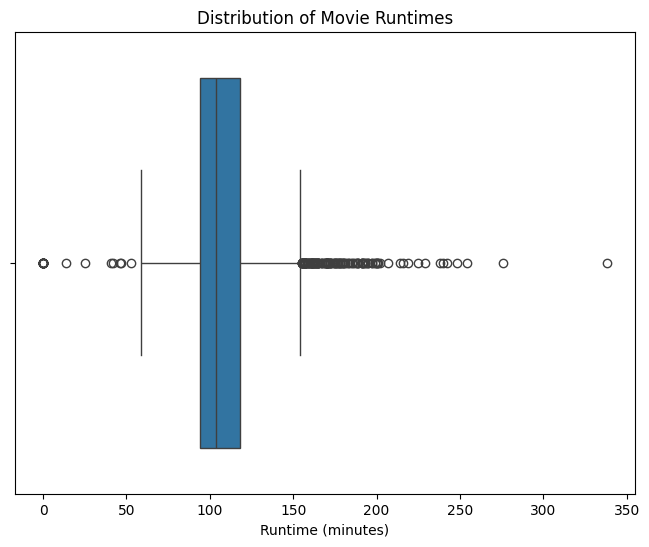

In [18]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='Movie_Runtime', data=df)
plt.title('Distribution of Movie Runtimes')
plt.xlabel('Runtime (minutes)')
plt.show()

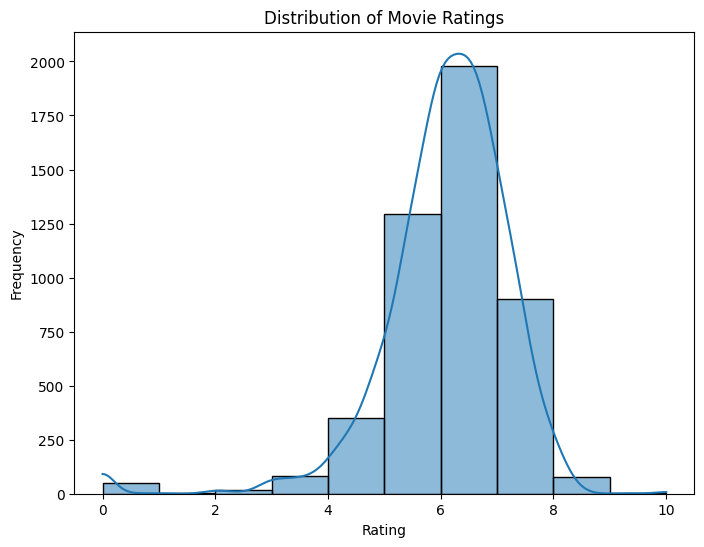

In [17]:
plt.figure(figsize=(8, 6))
sns.histplot(df['Movie_Vote'], bins=10, kde=True)
plt.title('Distribution of Movie Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.show()

## **Data Preprocessing**

In [12]:
df_features=df[['Movie_Genre','Movie_Tagline', 'Movie_Cast', 'Movie_Director','Movie_Overview']]

In [13]:
df_features.shape

(4760, 5)

In [51]:
df_features

,Movie_Genre,Movie_Tagline,Movie_Cast,Movie_Director,Movie_Overview
0,Crime Comedy,Twelve outrageous guests. Four scandalous requ...,Tim Roth Antonio Banderas Jennifer Beals Madon...,Allison Anders,It's Ted the Bellhop's first night on the job....
1,Adventure Action Science Fiction,"A long time ago in a galaxy far, far away...",Mark Hamill Harrison Ford Carrie Fisher Peter ...,George Lucas,Princess Leia is captured and held hostage by ...
2,Animation Family,"There are 3.7 trillion fish in the ocean, they...",Albert Brooks Ellen DeGeneres Alexander Gould ...,Andrew Stanton,"Nemo, an adventurous young clownfish, is unexp..."
3,Comedy Drama Romance,"The world will never be the same, once you've ...",Tom Hanks Robin Wright Gary Sinise Mykelti Wil...,Robert Zemeckis,A man with a low IQ has accomplished great thi...
4,Drama,Look closer.,Kevin Spacey Annette Bening Thora Birch Wes Be...,Sam Mendes,"Lester Burnham, a depressed suburban father in..."
...,...,...,...,...,...
4755,Horror,The hot spot where Satan's waitin'.,Lisa Hart Carroll Michael Des Barres Paul Drak...,Pece Dingo,A Broadway producer puts on a play with a Devi...
4756,Comedy Family Drama,It’s better to stand out than to fit in.,Roni Akurati Brighton Sharbino Jason Lee Anjul...,Frank Lotito,"In 1979, an Indian family moves to America wit..."
4757,Thriller Drama,She never knew it could happen to her...,Nicole Smolen Kim Baldwin Ariana Stephens Brys...,Jaco Booyens,"After sneaking to a party with her friends, 16..."
4758,Family,NaN,NaN,NaN,After being estranged since her mother's death...


In [52]:
X=df_features['Movie_Genre']+ ' ' +df_features['Movie_Tagline']+ ' ' +df_features['Movie_Cast']+ ' '+df_features['Movie_Director']+ ' '+df_features['Movie_Overview']

In [53]:
X.tail()

4755    Horror The hot spot where Satan's waitin'. Lis...
4756    Comedy Family Drama It’s better to stand out t...
4757    Thriller Drama She never knew it could happen ...
4758                                                  NaN
4759                                                  NaN
dtype: object

In [54]:
X.shape

(4760,)

In [69]:
X = X.dropna()

In [56]:
X.shape

(3926,)

In [57]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [58]:
tfidf=TfidfVectorizer()

In [59]:
X= tfidf.fit_transform(X)

In [60]:
X.shape

(3926, 25895)

In [61]:
print(X)

  (0, 1218)	0.09181201620701622
  (0, 673)	0.05872604349036507
  (0, 10318)	0.1345991756963977
  (0, 24071)	0.14506828287870396
  (0, 24344)	0.06012076405192716
  (0, 20573)	0.13601314894442504
  (0, 11940)	0.03352874435227373
  (0, 20569)	0.1172342439015981
  (0, 19670)	0.1233262602659048
  (0, 7952)	0.140955640674789
  (0, 23056)	0.06357070933935649
  (0, 22977)	0.044860233352539136
  (0, 20439)	0.10161457738216254
  (0, 17940)	0.16758377401063287
  (0, 21418)	0.08012635966301396
  (0, 10810)	0.058424894644738254
  (0, 17583)	0.0961327260176965
  (0, 23232)	0.024999961810952393
  (0, 378)	0.0680906194338253
  (0, 1394)	0.05409896970835144
  (0, 24329)	0.12975450984740627
  (0, 24612)	0.09634292768842326
  (0, 11066)	0.12108827720744891
  (0, 16093)	0.08754597146627024
  (0, 22811)	0.12496669419640814
  :	:
  (3925, 9706)	0.11751317292490135
  (3925, 16468)	0.09510435484065166
  (3925, 12791)	0.13622433129731
  (3925, 11819)	0.07480902300616782
  (3925, 1871)	0.0925079243411197
  (392

## **Define Target Variable (y) and Feature Variables (X)**

In [62]:
X=df_features['Movie_Genre']+ ' ' +df_features['Movie_Tagline']+ ' ' +df_features['Movie_Cast']+ ' '+df_features['Movie_Director']+ ' '+df_features['Movie_Overview']

## **Train Test Split**

In [64]:
print(df_features.head())

                        Movie_Genre  \
0                      Crime Comedy   
1  Adventure Action Science Fiction   
2                  Animation Family   
3              Comedy Drama Romance   
4                             Drama   

                                       Movie_Tagline  \
0  Twelve outrageous guests. Four scandalous requ...   
1       A long time ago in a galaxy far, far away...   
2  There are 3.7 trillion fish in the ocean, they...   
3  The world will never be the same, once you've ...   
4                                       Look closer.   

                                          Movie_Cast   Movie_Director  \
0  Tim Roth Antonio Banderas Jennifer Beals Madon...   Allison Anders   
1  Mark Hamill Harrison Ford Carrie Fisher Peter ...     George Lucas   
2  Albert Brooks Ellen DeGeneres Alexander Gould ...   Andrew Stanton   
3  Tom Hanks Robin Wright Gary Sinise Mykelti Wil...  Robert Zemeckis   
4  Kevin Spacey Annette Bening Thora Birch Wes Be...       Sam 

## **Modeling**

In [71]:
X=df_features['Movie_Genre']+ ' ' +df_features['Movie_Tagline']+ ' ' +df_features['Movie_Cast']+ ' '+df_features['Movie_Director']+ ' '+df_features['Movie_Overview']
from sklearn.feature_extraction.text import TfidfVectorizer
X = X.dropna()

tfidf=TfidfVectorizer()
X= tfidf.fit_transform(X)




from sklearn.metrics.pairwise import cosine_similarity

similarity_score=cosine_similarity(X)
similarity_score

array([[1.        , 0.03019643, 0.0354479 , ..., 0.05612383, 0.04088595,
        0.026772  ],
       [0.03019643, 1.        , 0.01825603, ..., 0.02197554, 0.03828229,
        0.01755374],
       [0.0354479 , 0.01825603, 1.        , ..., 0.0132259 , 0.03511382,
        0.0161314 ],
       ...,
       [0.05612383, 0.02197554, 0.0132259 , ..., 1.        , 0.01451347,
        0.02468111],
       [0.04088595, 0.03828229, 0.03511382, ..., 0.01451347, 1.        ,
        0.05752157],
       [0.026772  , 0.01755374, 0.0161314 , ..., 0.02468111, 0.05752157,
        1.        ]])

In [72]:
similarity_score.shape

(3926, 3926)

In [73]:
favourite_movie_name=input('Enter your favourite movie name:')

Enter your favourite movie name:avatar


In [74]:
list_of_all_titles=df['Movie_Title'].tolist()

In [75]:
import difflib
movie_recommendation=difflib.get_close_matches(favourite_movie_name,list_of_all_titles)
print(movie_recommendation)

['Avatar']


In [76]:
close_match=movie_recommendation[0]
print(close_match)

Avatar


In [77]:
index_of_close_match_movies=df[df.Movie_Title==close_match]['Movie_ID'].values[0]
print(index_of_close_match_movies)

2692


In [78]:
recommendation_score=list(enumerate(similarity_score[index_of_close_match_movies]))
print(recommendation_score)

[(0, 0.037764745680847665), (1, 0.0552341873075835), (2, 0.03903051140108588), (3, 0.06562073978244501), (4, 0.02623772822657153), (5, 0.0555247510904953), (6, 0.04574880989589152), (7, 0.043101546587791445), (8, 0.05637684315006838), (9, 0.036031734662591235), (10, 0.05749713465709563), (11, 0.03666803369898487), (12, 0.03165999076844604), (13, 0.026830278656209988), (14, 0.05254596177768716), (15, 0.024684871777002036), (16, 0.03632427896214481), (17, 0.02717995720072364), (18, 0.037518127077259544), (19, 0.07805625308735196), (20, 0.0447212519082175), (21, 0.055724948660402195), (22, 0.03917692111390436), (23, 0.055465516105633855), (24, 0.06771150755399379), (25, 0.04329223699721558), (26, 0.03524632001730628), (27, 0.030685180350725025), (28, 0.025931035392825437), (29, 0.046001771546857195), (30, 0.040251868239372685), (31, 0.02126516730352742), (32, 0.032585351940324386), (33, 0.017617945822002247), (34, 0.054518857105097455), (35, 0.043412505816800714), (36, 0.05439424649192535

In [79]:
len(recommendation_score)

3926

## **Model Evaluation**

In [80]:
sorted_similar_movies=sorted(recommendation_score,key=lambda x:x[1],reverse=True)
print(sorted_similar_movies)

[(2692, 1.0000000000000002), (3231, 0.10844697332352432), (3588, 0.1059772142741307), (2601, 0.09817973910995786), (3272, 0.09809450258080234), (2152, 0.09788384274253617), (2047, 0.0976976908975761), (3279, 0.0974792466308689), (700, 0.0969065457479843), (2087, 0.09523114649156685), (2942, 0.0944300215518276), (3426, 0.09432492681098816), (766, 0.09277632995545822), (2275, 0.09245851195108545), (2863, 0.09225752618271149), (2693, 0.09137360144280185), (2277, 0.09079925182536856), (1771, 0.09073179478344015), (39, 0.0905577178724375), (3492, 0.0895912810429282), (3161, 0.08897632600359572), (1480, 0.08874451521001407), (2600, 0.08774446165909312), (2874, 0.08751207355037006), (1868, 0.08713683897691174), (1541, 0.08675272207713662), (3353, 0.08665161188523894), (1715, 0.08658046121907742), (3407, 0.08646465079494306), (2400, 0.08601014589387412), (2243, 0.08554293126914787), (2860, 0.08539553001026046), (807, 0.0843564543381374), (3558, 0.08430068252022216), (1958, 0.08399836698408916)

In [81]:
print('Top 30 movies suggested for you: \n')
i=1
for movie in sorted_similar_movies:
  index=movie[0]
  title_from_index=df[df.index==index]['Movie_Title'].values[0]
  if(i<31):
    print(i,'.',title_from_index)
    i+=1

Top 30 movies suggested for you: 

1 . Niagara
2 . Paul
3 . The Hit List
4 . Duets
5 . Legend of the Guardians: The Owls of Ga'Hoole
6 . The Torture Chamber of Dr. Sadism
7 . The Color of Money
8 . Paranormal Activity 2
9 . Stardust
10 . It's All Gone Pete Tong
11 . The Nun's Story
12 . Sphinx
13 . A Very Long Engagement
14 . Exiled
15 . Julie & Julia
16 . Slackers
17 . Knowing
18 . Elf
19 . Armageddon
20 . The Twilight Saga: Breaking Dawn - Part 2
21 . The Tourist
22 . Urban Legend
23 . Next Day Air
24 . Drowning Mona
25 . Blazing Saddles
26 . Honey
27 . Hereafter
28 . East Is East
29 . Speedway Junky
30 . The Haunting of Molly Hartley


## **Prediction**

In [82]:
movie_name=input('Enter your favourite movie name:')
list_of_all_titles=df['Movie_Title'].tolist()
find_close_match=difflib.get_close_matches(movie_name,list_of_all_titles)

close_Match=find_close_match[0]
index_of_movie=df[df.Movie_Title==close_Match]['Movie_ID'].values[0]
recommendation_score=list(enumerate(similarity_score[index_of_movie]))
sorted_similar_movies=sorted(recommendation_score,key=lambda x:x[1],reverse=True)

print('Top 10 movies suggested for you: \n')
i=1
for movie in sorted_similar_movies:
  index=movie[0]
  title_from_index=df[df.index==index]['Movie_Title'].values[0]
  if(i<11):
    print(i,'.',title_from_index)
    i+=1

Enter your favourite movie name:Avatar
Top 10 movies suggested for you: 

1 . Niagara
2 . Paul
3 . The Hit List
4 . Duets
5 . Legend of the Guardians: The Owls of Ga'Hoole
6 . The Torture Chamber of Dr. Sadism
7 . The Color of Money
8 . Paranormal Activity 2
9 . Stardust
10 . It's All Gone Pete Tong


## **Explaination**

# Project Overview

This notebook implements a movie recommendation system using a dataset containing various attributes of movies. The goal is to recommend movies to users based on the similarity between the movies they like and other movies in the dataset.

## Dataset

The dataset includes the following columns:

- **Movie_ID**: Unique identifier for each movie.
- **Movie_Title**: Title of the movie.
- **Movie_Genre**: Genre of the movie.
- **Movie_Language**: Language in which the movie is produced.
- **Movie_Budget**: Budget of the movie.
- **Movie_Popularity**: Measure of the movie's popularity.
- **Movie_Release_Date**: Release date of the movie.
- **Movie_Revenue**: Revenue generated by the movie.
- **Movie_Runtime**: Runtime of the movie.
- **Movie_Vote**: Average vote the movie received.
- **Movie_Vote_Count**: Number of votes the movie received.
- **Movie_Homepage**: Official homepage of the movie.
- **Movie_Keywords**: Keywords associated with the movie.
- **Movie_Overview**: Brief overview of the movie.
- **Movie_Production_House**: Production house that produced the movie.
- **Movie_Production_Country**: Country where the movie was produced.
- **Movie_Spoken_Language**: Language spoken in the movie.
- **Movie_Tagline**: Tagline of the movie.
- **Movie_Cast**: Main cast of the movie.
- **Movie_Crew**: Crew members of the movie.
- **Movie_Director**: Director of the movie.

## Methodology

1. **Data Loading**: The dataset is loaded and preprocessed to ensure it is ready for analysis.
2. **Similarity Score Calculation**: Cosine similarity is used to calculate a similarity score between movies based on relevant features. This score helps in identifying movies that are similar to each other.
3. **User Input**: The user is prompted to enter the name of a movie they like.
4. **Recommendation Generation**: Based on the user's input, the system finds the closest matching movie in the dataset and recommends a list of similar movies. Recommendations are sorted by similarity score in descending order.

## Code Implementation

1. **Data Loading**: The dataset is loaded using pandas and undergoes necessary cleaning and preprocessing.
2. **Similarity Calculation**: Cosine similarity between movies is calculated using relevant features from the dataset.
3. **User Interaction**: The system takes a movie name as input from the user, finds the closest match, and generates a list of recommended movies.

## Results

The notebook outputs the top 10 movie recommendations based on the user's input. For example, if the user enters "Toy Story," the system may recommend movies like "Toy Story 2," "Mulan," and "End of Days."

## Conclusion

This project demonstrates a basic implementation of a movie recommendation system using similarity scores. The recommendations are based on the assumption that movies with similar attributes are likely to be enjoyed by the same audience.